# IPL Team Performance Analysis – Data Analytics Case Study

**Team members:** _(add names here)_
**Module:** Data Analytics

**Dataset:** IPL Complete Dataset (2008 onwards) – Kaggle, by Patrick B (`patrickb1912/ipl-complete-dataset-20082020`)
- `deliveries.csv` – one row per ball bowled (~260,000 rows, 17 columns). **This is the main dataset of the study.** Every team metric (run rate, boundaries, dot balls, economy, wickets, phase-wise scoring) is calculated from it.
- `matches.csv` – one row per match (~1,100 rows, 20 columns). Used only for context: season, winner and venue.

**Contents**
1. Business problem
2. Data understanding, cleaning & preparation
3. Exploratory data analysis (ball-by-ball)
4. Team performance profiles (batting, bowling, phases)
5. Hypothesis testing
6. Team Performance Index (rule-based, transparent)
7. Business insights
8. Recommendations

## 1. Business Problem

An IPL franchise spends crores at the auction and wants to know **where its team is strong, where it is weak, and what actually separates winning performances from losing ones**. Broadcasters and fantasy platforms need the same information to tell stories about teams and to price their products.

Win/loss alone is a poor measure of performance: a team can lose after a great batting display, or win with an average one. Ball-by-ball data lets us measure *how* a team performs, not only *whether* it won.

**Questions we want to answer**
1. How do the 10+ IPL franchises compare on batting (run rate, boundaries, dot balls) and bowling (economy, strike rate, wickets)?
2. In which phase of the innings (powerplay, middle overs, death overs) is each team strong or weak?
3. Do teams perform differently when batting first versus chasing?
4. Which on-field performance measures separate winning innings from losing ones – and are the differences statistically significant?
5. How has team performance and scoring changed over the seasons?
6. Can we build a simple, explainable **Team Performance Index** from ball-by-ball statistics, and does it agree with actual win percentage?

## 2. Data Understanding, Cleaning & Preparation

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [3]:
# change these paths if your files are somewhere else
MATCHES_PATH = "matches.csv"
DELIVERIES_PATH = "deliveries.csv"

matches = pd.read_csv(MATCHES_PATH)
deliveries = pd.read_csv(DELIVERIES_PATH)

print("deliveries :", deliveries.shape, " <- main dataset (rows x columns)")
print("matches    :", matches.shape, " <- context only")
print()
print(deliveries.columns.tolist())

deliveries : (260920, 17)  <- main dataset (rows x columns)
matches    : (1095, 20)  <- context only

['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


In [4]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [5]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [6]:
deliveries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260920 entries, 0 to 260919
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   match_id          260920 non-null  int64 
 1   inning            260920 non-null  int64 
 2   batting_team      260920 non-null  object
 3   bowling_team      260920 non-null  object
 4   over              260920 non-null  int64 
 5   ball              260920 non-null  int64 
 6   batter            260920 non-null  object
 7   bowler            260920 non-null  object
 8   non_striker       260920 non-null  object
 9   batsman_runs      260920 non-null  int64 
 10  extra_runs        260920 non-null  int64 
 11  total_runs        260920 non-null  int64 
 12  extras_type       14125 non-null   object
 13  is_wicket         260920 non-null  int64 
 14  player_dismissed  12950 non-null   object
 15  dismissal_kind    12950 non-null   object
 16  fielder           9354 non-null    obj

In [7]:
# missing values in both tables
print("--- deliveries ---")
print(deliveries.isnull().sum()[deliveries.isnull().sum() > 0])
print()
print("--- matches ---")
print(matches.isnull().sum()[matches.isnull().sum() > 0])

--- deliveries ---
extras_type         246795
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64

--- matches ---
city                 51
player_of_match       5
winner                5
result_margin        19
target_runs           3
target_overs          3
method             1074
dtype: int64


**What we see**
- In `deliveries`, `extras_type`, `player_dismissed`, `dismissal_kind` and `fielder` are blank for most balls. That is normal (no extra, no wicket on that ball) and not an error.
- In `matches`, missing `winner` / `city` are mostly no-result or abandoned games.

**Key `deliveries` columns used**

| Column | Meaning | How we use it |
|---|---|---|
| `match_id`, `inning` | which match / which innings | group balls into innings |
| `batting_team`, `bowling_team` | the two sides | team-level batting and bowling metrics |
| `over` | over number | split into powerplay / middle / death phases |
| `batsman_runs`, `extra_runs`, `total_runs` | runs off the bat, extras, total | run rate, boundaries, dot balls, runs conceded |
| `extras_type` | wides, no-balls, byes, leg-byes, penalty | decide which balls are *legal* and which runs are charged to the bowler |
| `is_wicket`, `dismissal_kind` | wicket and how | wickets lost, wickets taken by bowlers |

### Cleaning steps
1. Franchises changed their names over the years, so we standardise them.
2. Make sure `over` runs from 0 to 19.
3. Keep only the two main innings (ignore super overs).
4. Keep only matches with a result, so that every innings can be labelled as a win or a loss.
5. Remove duplicate rows if any.

In [8]:
# same team, different names over the years
team_fix = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
}

for col in ["team1", "team2", "toss_winner", "winner"]:
    matches[col] = matches[col].replace(team_fix)

for col in ["batting_team", "bowling_team"]:
    deliveries[col] = deliveries[col].replace(team_fix)

matches["date"] = pd.to_datetime(matches["date"])
matches["year"] = matches["date"].dt.year

# duplicates
print("duplicate matches   :", matches.duplicated().sum())
print("duplicate deliveries:", deliveries.duplicated().sum())
deliveries = deliveries.drop_duplicates()

# some versions of the file count overs from 1, we want 0-19
if deliveries["over"].min() == 1:
    deliveries["over"] = deliveries["over"] - 1

# keep only the two main innings (ignore super overs)
deliveries = deliveries[deliveries["inning"].isin([1, 2])].copy()

# matches with a result only
before = len(matches)
matches = matches[matches["winner"].notna()].copy()
print(f"dropped {before - len(matches)} matches with no winner, {len(matches)} left")

# attach season / winner / venue to every ball (this is the working ball-by-ball table)
bb = deliveries.merge(matches[["id", "year", "winner", "venue"]],
                      left_on="match_id", right_on="id", how="inner").drop(columns="id")
print("ball-by-ball rows used:", bb.shape)

duplicate matches   : 0
duplicate deliveries: 0
dropped 5 matches with no winner, 1090 left
ball-by-ball rows used: (260269, 20)


### Creating ball-level features
Cricket has some details that matter when we turn raw rows into team statistics:
- **Legal ball:** wides and no-balls do not count as one of the 6 balls in an over, so run rate is `runs / legal balls x 6`.
- **Runs charged to the bowler:** byes, leg-byes and penalty runs are *not* charged to the bowler, so economy uses a separate `bowler_runs` column.
- **Wickets credited to the bowler:** run-outs, retired and obstructing-the-field are not bowling wickets.
- **Phases:** powerplay = overs 1-6, middle = overs 7-16, death = overs 17-20.

In [9]:
bb["extras_type"] = bb["extras_type"].fillna("none")

bb["legal"] = (~bb["extras_type"].isin(["wides", "noballs"])).astype(int)
bb["illegal"] = 1 - bb["legal"]                      # wides + no-balls

# runs that count against the bowler
bb["bowler_runs"] = np.where(bb["extras_type"].isin(["byes", "legbyes", "penalty"]),
                             bb["total_runs"] - bb["extra_runs"], bb["total_runs"])

bb["is_dot"] = ((bb["total_runs"] == 0) & (bb["legal"] == 1)).astype(int)
bb["is_four"] = (bb["batsman_runs"] == 4).astype(int)
bb["is_six"] = (bb["batsman_runs"] == 6).astype(int)
bb["is_boundary"] = ((bb["batsman_runs"] == 4) | (bb["batsman_runs"] == 6)).astype(int)

not_bowler_wkt = ["run out", "retired hurt", "retired out", "obstructing the field"]
bb["bowler_wkt"] = ((bb["is_wicket"] == 1) & (~bb["dismissal_kind"].isin(not_bowler_wkt))).astype(int)

PHASES = ["Powerplay (1-6)", "Middle (7-16)", "Death (17-20)"]
bb["phase"] = pd.cut(bb["over"], bins=[-1, 5, 15, 19], labels=PHASES)

bb[["match_id", "inning", "batting_team", "bowling_team", "over", "total_runs",
    "legal", "bowler_runs", "is_dot", "is_boundary", "bowler_wkt", "phase"]].head()

,match_id,inning,batting_team,bowling_team,over,total_runs,legal,bowler_runs,is_dot,is_boundary,bowler_wkt,phase
0,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,1,1,0,0,0,0,Powerplay (1-6)
1,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,0,1,0,1,0,0,Powerplay (1-6)
2,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,1,0,1,0,0,0,Powerplay (1-6)
3,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,0,1,0,1,0,0,Powerplay (1-6)
4,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,0,1,0,1,0,0,Powerplay (1-6)


### Innings-level table
One row per innings per team: runs, balls, wickets, boundaries, dot balls and run rate in each phase. We also attach the match result so every innings is labelled as part of a win or a loss. This table is the base for the hypothesis tests.

In [10]:
inn = (bb.groupby(["match_id", "inning", "batting_team", "bowling_team"])
         .agg(runs=("total_runs", "sum"), balls=("legal", "sum"), wkts=("is_wicket", "sum"),
              dots=("is_dot", "sum"), boundaries=("is_boundary", "sum"), sixes=("is_six", "sum"),
              conceded=("bowler_runs", "sum"), bowler_wkts=("bowler_wkt", "sum"),
              wd_nb=("illegal", "sum"))
         .reset_index())


def phase_stat(label, short):
    x = (bb[bb["phase"] == label].groupby(["match_id", "inning"])
           .agg(**{f"{short}_runs": ("total_runs", "sum"),
                   f"{short}_balls": ("legal", "sum"),
                   f"{short}_wkts": ("is_wicket", "sum")}))
    x[f"{short}_rr"] = x[f"{short}_runs"] / x[f"{short}_balls"] * 6
    return x


for label, short in zip(PHASES, ["pp", "mid", "death"]):
    inn = inn.merge(phase_stat(label, short), on=["match_id", "inning"], how="left")

inn = inn.merge(matches[["id", "year", "winner"]], left_on="match_id", right_on="id", how="left").drop(columns="id")

inn["won"] = (inn["batting_team"] == inn["winner"]).astype(int)
inn["run_rate"] = inn["runs"] / inn["balls"] * 6
inn["dot_pct"] = inn["dots"] / inn["balls"] * 100
inn["boundary_pct"] = inn["boundaries"] / inn["balls"] * 100

print(inn.shape)
inn[["year", "batting_team", "inning", "runs", "balls", "wkts", "run_rate", "pp_rr", "mid_rr", "death_rr", "dot_pct", "won"]].head()

(2180, 31)


,year,batting_team,inning,runs,balls,wkts,run_rate,pp_rr,mid_rr,death_rr,dot_pct,won
0,2008,Kolkata Knight Riders,1,222,120,3,11.100000,10.166667,9.700000,16.00,30.000000,1
1,2008,Royal Challengers Bengaluru,2,82,91,10,5.406593,4.333333,6.109091,NaN,54.945055,0
2,2008,Chennai Super Kings,1,240,120,5,12.000000,8.833333,11.600000,17.75,28.333333,1
3,2008,Punjab Kings,2,207,120,4,10.350000,10.500000,11.300000,7.75,19.166667,0
4,2008,Rajasthan Royals,1,129,120,8,6.450000,6.666667,6.600000,5.75,45.000000,0


In [11]:
inn[["runs", "balls", "wkts", "run_rate", "pp_rr", "mid_rr", "death_rr", "dot_pct", "boundary_pct"]].describe().round(2)

,runs,balls,wkts,run_rate,pp_rr,mid_rr,death_rr,dot_pct,boundary_pct
count,2180.00,2180.00,2180.00,2180.00,2180.00,2173.00,2036.00,2180.00,2180.00
mean,159.08,115.07,5.91,8.32,7.85,7.92,10.25,36.06,17.17
std,32.19,11.74,2.45,1.55,2.10,1.85,3.63,7.47,5.25
min,44.00,26.00,0.00,3.82,2.33,2.73,0.00,15.83,2.50
25%,139.00,116.00,4.00,7.24,6.33,6.60,8.00,30.83,13.33
50%,160.00,120.00,6.00,8.25,7.83,7.80,10.00,35.62,16.67
75%,180.00,120.00,8.00,9.30,9.17,9.00,12.32,40.68,20.58
max,287.00,121.00,10.00,17.28,20.83,16.44,36.00,68.04,51.72


## 3. Exploratory Data Analysis (ball-by-ball)

In [12]:
# the size of the data in cricket terms
print(f"Balls bowled (incl. wides/no-balls): {len(bb):,}")
print(f"Legal balls                        : {bb['legal'].sum():,}")
print(f"Runs scored                        : {bb['total_runs'].sum():,}")
print(f"Wickets fallen                     : {bb['is_wicket'].sum():,}")
print(f"Fours / Sixes                      : {bb['is_four'].sum():,} / {bb['is_six'].sum():,}")
print(f"Dot-ball share of legal balls      : {bb['is_dot'].sum() / bb['legal'].sum() * 100:.1f}%")
print(f"Overall run rate                   : {bb['total_runs'].sum() / bb['legal'].sum() * 6:.2f} runs/over")

Balls bowled (incl. wides/no-balls): 260,269
Legal balls                        : 250,845
Runs scored                        : 346,797
Wickets fallen                     : 12,893
Fours / Sixes                      : 29,770 / 13,009
Dot-ball share of legal balls      : 36.0%
Overall run rate                   : 8.30 runs/over


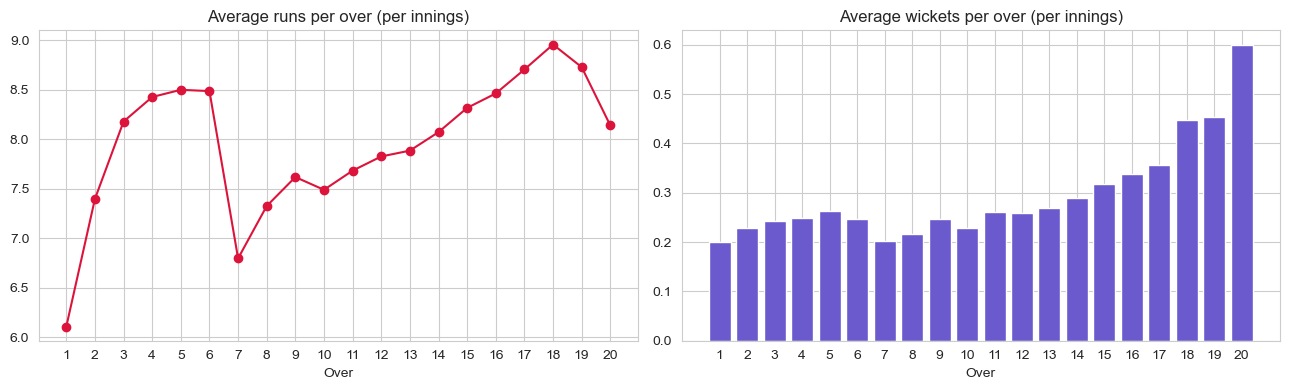

In [13]:
# runs and wickets in each over (average per innings)
n_inn = inn.shape[0]
runs_per_over = bb.groupby("over")["total_runs"].sum() / n_inn
wkts_per_over = bb.groupby("over")["is_wicket"].sum() / n_inn

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(runs_per_over.index + 1, runs_per_over.values, marker="o", color="crimson")
ax[0].set_title("Average runs per over (per innings)")
ax[0].set_xlabel("Over"); ax[0].set_xticks(range(1, 21))

ax[1].bar(wkts_per_over.index + 1, wkts_per_over.values, color="slateblue")
ax[1].set_title("Average wickets per over (per innings)")
ax[1].set_xlabel("Over"); ax[1].set_xticks(range(1, 21))
plt.tight_layout()
plt.show()

Scoring climbs through the powerplay and shoots up in the last four overs, and wickets also fall faster at the end because batters take more risk. That is why we split every innings into three phases.

In [14]:
# how much of the total score comes from each phase, and how fast
phase_tbl = bb.groupby("phase", observed=True).agg(runs=("total_runs", "sum"), balls=("legal", "sum"),
                                                    wkts=("is_wicket", "sum"), dots=("is_dot", "sum"),
                                                    boundaries=("is_boundary", "sum"))
phase_tbl["share_of_runs_%"] = phase_tbl["runs"] / phase_tbl["runs"].sum() * 100
phase_tbl["run_rate"] = phase_tbl["runs"] / phase_tbl["balls"] * 6
phase_tbl["dot_%"] = phase_tbl["dots"] / phase_tbl["balls"] * 100
phase_tbl["boundary_%"] = phase_tbl["boundaries"] / phase_tbl["balls"] * 100
phase_tbl["balls_per_wkt"] = phase_tbl["balls"] / phase_tbl["wkts"]
phase_tbl[["share_of_runs_%", "run_rate", "dot_%", "boundary_%", "balls_per_wkt"]].round(2)

,share_of_runs_%,run_rate,dot_%,boundary_%,balls_per_wkt
phase,,,,,
Powerplay (1-6),29.60,7.85,46.98,19.65,25.14
Middle (7-16),48.69,7.90,31.90,14.01,22.40
Death (17-20),21.70,10.23,28.22,21.28,10.91


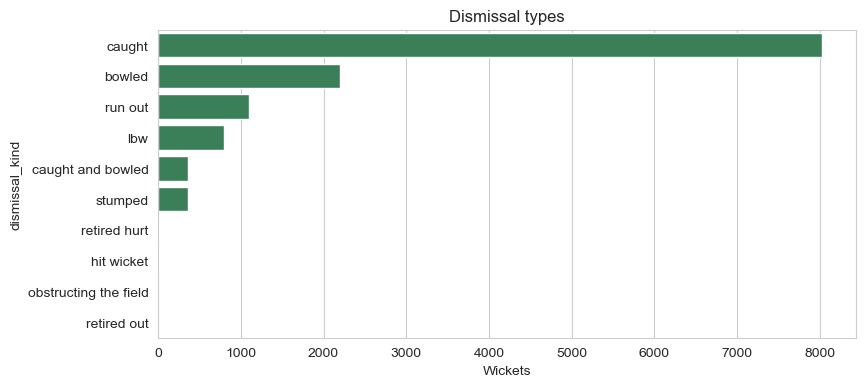

In [15]:
# how are wickets taken?
dk = bb[bb["is_wicket"] == 1]["dismissal_kind"].value_counts()

plt.figure(figsize=(9, 4))
sns.barplot(x=dk.values, y=dk.index, color="seagreen")
plt.title("Dismissal types")
plt.xlabel("Wickets")
plt.show()

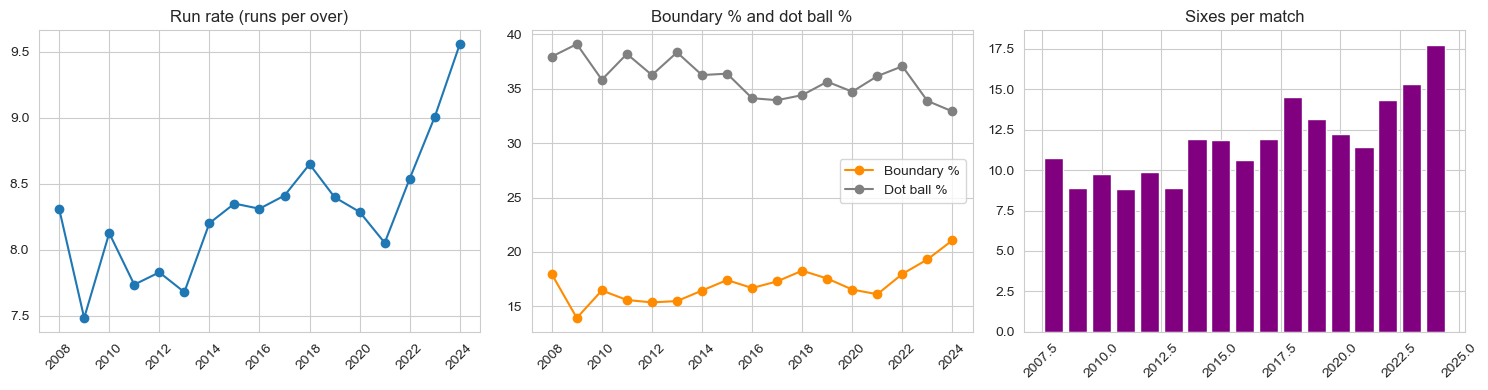

,run_rate,boundary_%,dot_%,sixes_per_match
year,,,,
2008,8.31,17.96,37.96,10.74
2009,7.48,13.93,39.11,8.88
2010,8.13,16.46,35.84,9.75
2011,7.74,15.58,38.21,8.85
2012,7.83,15.36,36.27,9.91
2013,7.68,15.48,38.35,8.88
2014,8.20,16.45,36.27,11.90
2015,8.35,17.42,36.40,11.89
2016,8.31,16.68,34.14,10.65


In [16]:
# how has scoring changed over the years? (all numbers from the ball-by-ball data)
yr = bb.groupby("year").agg(runs=("total_runs", "sum"), balls=("legal", "sum"), dots=("is_dot", "sum"),
                            bnd=("is_boundary", "sum"), sixes=("is_six", "sum"))
yr["run_rate"] = yr["runs"] / yr["balls"] * 6
yr["boundary_%"] = yr["bnd"] / yr["balls"] * 100
yr["dot_%"] = yr["dots"] / yr["balls"] * 100
yr["sixes_per_match"] = yr["sixes"] / bb.groupby("year")["match_id"].nunique()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(yr.index, yr["run_rate"], marker="o"); ax[0].set_title("Run rate (runs per over)")
ax[1].plot(yr.index, yr["boundary_%"], marker="o", color="darkorange", label="Boundary %")
ax[1].plot(yr.index, yr["dot_%"], marker="o", color="grey", label="Dot ball %")
ax[1].set_title("Boundary % and dot ball %"); ax[1].legend()
ax[2].bar(yr.index, yr["sixes_per_match"], color="purple"); ax[2].set_title("Sixes per match")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
yr[["run_rate", "boundary_%", "dot_%", "sixes_per_match"]].round(2)

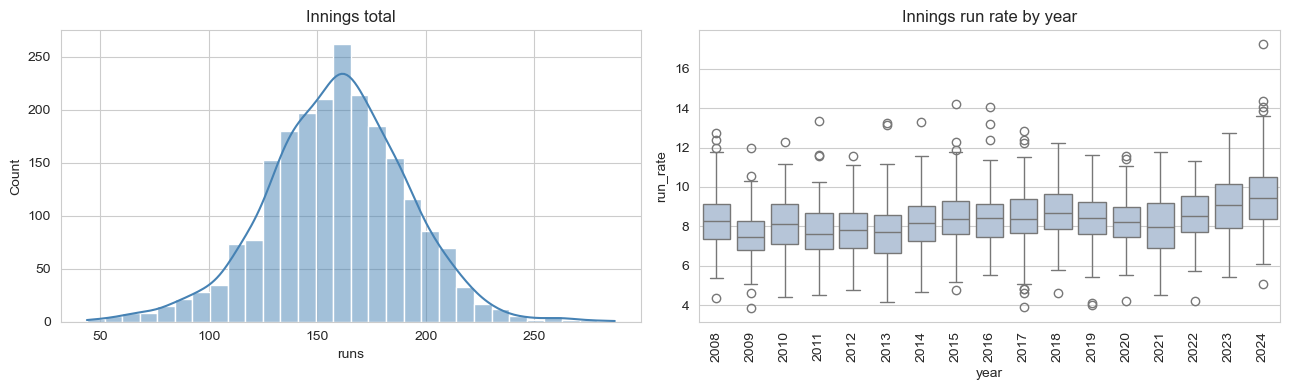

In [17]:
# distribution of innings totals and run rate by season
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(inn["runs"], bins=30, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Innings total")
sns.boxplot(data=inn, x="year", y="run_rate", ax=ax[1], color="lightsteelblue")
ax[1].set_title("Innings run rate by year")
ax[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

## 4. Team Performance Profiles

We now build the team scorecards. Every number comes from `deliveries.csv`.
- **Batting:** run rate, runs per wicket, boundary % and dot-ball % of balls faced, plus run rate in each phase.
- **Bowling:** economy, bowling strike rate (balls per wicket), dot-ball % bowled, wides + no-balls per over, plus economy in each phase.
- **Record:** matches played and win % from the match results, used later to check whether our measures agree with winning.

In [19]:
def batting_metrics(keys):
    # keys = ["batting_team"] (whole history) or ["batting_team", "year"] (team-season)
    g = bb.groupby(keys).agg(runs=("total_runs", "sum"), balls=("legal", "sum"), wkts=("is_wicket", "sum"),
                             dots=("is_dot", "sum"), bnd=("is_boundary", "sum"))
    out = pd.DataFrame({
        "bat_rr": g["runs"] / g["balls"] * 6,
        "runs_per_wkt": g["runs"] / g["wkts"].clip(lower=1),
        "bat_boundary_pct": g["bnd"] / g["balls"] * 100,
        "bat_dot_pct": g["dots"] / g["balls"] * 100,
    })
    pg = bb.groupby(keys + ["phase"], observed=True).agg(runs=("total_runs", "sum"), balls=("legal", "sum"))
    prr = (pg["runs"] / pg["balls"] * 6).unstack("phase")
    prr.columns = ["pp_rr", "mid_rr", "death_rr"]
    out = out.join(prr)
    out.index.names = ["team", "year"][:len(keys)]
    return out


def bowling_metrics(keys):
    # keys = ["bowling_team"] or ["bowling_team", "year"]
    g = bb.groupby(keys).agg(conceded=("bowler_runs", "sum"), balls=("legal", "sum"), wkts=("bowler_wkt", "sum"),
                             dots=("is_dot", "sum"), wd_nb=("illegal", "sum"))
    out = pd.DataFrame({
        "econ": g["conceded"] / g["balls"] * 6,
        "bowl_sr": g["balls"] / g["wkts"].clip(lower=1),
        "bowl_dot_pct": g["dots"] / g["balls"] * 100,
        "extras_per_over": g["wd_nb"] / g["balls"] * 6,
    })
    pg = bb.groupby(keys + ["phase"], observed=True).agg(conceded=("bowler_runs", "sum"), balls=("legal", "sum"))
    pe = (pg["conceded"] / pg["balls"] * 6).unstack("phase")
    pe.columns = ["pp_econ", "mid_econ", "death_econ"]
    out = out.join(pe)
    out.index.names = ["team", "year"][:len(keys)]
    return out


# win / loss record per team and per team-season
long = pd.concat([
    matches[["id", "year", "team1", "winner"]].rename(columns={"team1": "team"}),
    matches[["id", "year", "team2", "winner"]].rename(columns={"team2": "team"}),
])
long["won"] = (long["team"] == long["winner"]).astype(int)

overall_record = long.groupby("team").agg(matches=("id", "count"), wins=("won", "sum"))
overall_record["win_pct"] = overall_record["wins"] / overall_record["matches"] * 100

season_record = long.groupby(["team", "year"]).agg(matches=("id", "count"), wins=("won", "sum"))
season_record["win_pct"] = season_record["wins"] / season_record["matches"] * 100

# whole-history team table; keep franchises with a decent sample
team_overall = (batting_metrics(["batting_team"]).join(bowling_metrics(["bowling_team"]))
                .join(overall_record))
team_overall = team_overall[team_overall["matches"] >= 30].sort_values("win_pct", ascending=False)
print("teams with >= 30 matches:", len(team_overall))
team_overall.round(2)

teams with >= 30 matches: 14


,bat_rr,runs_per_wkt,bat_boundary_pct,bat_dot_pct,pp_rr,mid_rr,death_rr,econ,bowl_sr,bowl_dot_pct,extras_per_over,pp_econ,mid_econ,death_econ,matches,wins,win_pct
team,,,,,,,,,,,,,,,,,
Gujarat Titans,8.83,31.40,18.25,31.54,8.08,8.37,11.37,8.61,18.69,36.01,0.19,8.39,8.30,9.90,45,28,62.22
Chennai Super Kings,8.39,31.07,17.03,35.03,7.72,7.91,10.87,7.97,20.26,36.44,0.23,7.73,7.52,9.70,237,138,58.23
Lucknow Super Giants,8.80,27.45,17.86,34.46,7.94,8.55,10.95,8.73,20.20,35.46,0.26,8.85,7.93,10.72,43,24,55.81
Mumbai Indians,8.36,26.87,17.59,36.96,7.78,7.91,10.69,8.02,20.79,36.56,0.24,7.35,7.89,9.60,261,144,55.17
Kolkata Knight Riders,8.31,26.43,17.46,36.97,7.91,7.95,10.18,8.02,21.55,36.22,0.21,7.75,7.55,9.89,251,131,52.19
Rajasthan Royals,8.23,26.49,17.07,36.67,7.72,7.97,9.90,8.13,22.08,35.59,0.25,7.51,7.77,10.28,219,112,51.14
Rising Pune Supergiant,8.09,28.69,15.61,33.80,7.91,7.42,10.40,7.86,20.12,36.17,0.22,7.85,7.06,10.18,30,15,50.00
Royal Challengers Bengaluru,8.41,27.45,17.33,35.76,7.70,8.05,10.74,8.27,21.26,35.86,0.24,7.75,7.91,10.29,252,123,48.81
Sunrisers Hyderabad,8.28,27.55,16.37,34.51,8.16,7.79,9.88,8.17,21.35,35.94,0.20,7.66,7.91,9.80,182,88,48.35


### 4.1 Batting vs bowling – where does each team sit?
The top-left of the chart (high run rate, low economy) is the ideal place. The x-axis is flipped so that "better bowling" is to the right.

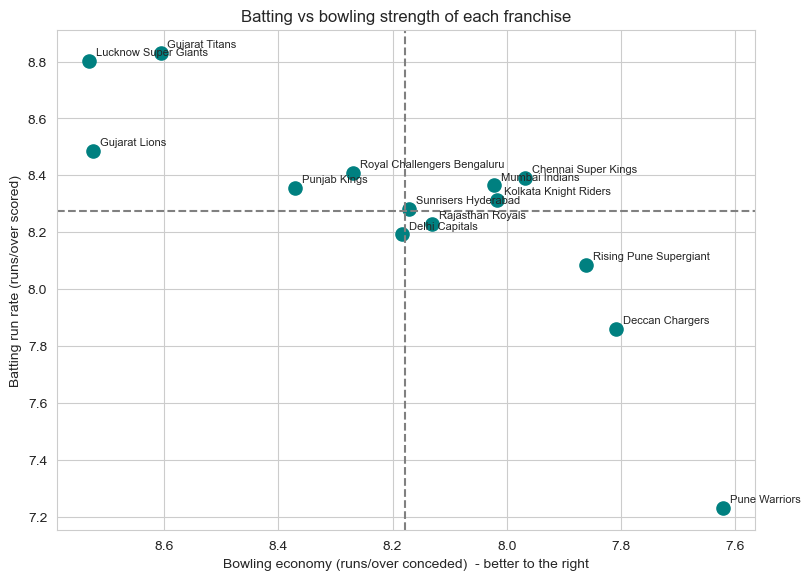

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(team_overall["econ"], team_overall["bat_rr"], s=90, color="teal")
for t, r in team_overall.iterrows():
    ax.annotate(t, (r["econ"], r["bat_rr"]), fontsize=8, xytext=(5, 4), textcoords="offset points")
ax.axvline(team_overall["econ"].mean(), color="grey", linestyle="--")
ax.axhline(team_overall["bat_rr"].mean(), color="grey", linestyle="--")
ax.invert_xaxis()
ax.set_xlabel("Bowling economy (runs/over conceded)  - better to the right")
ax.set_ylabel("Batting run rate (runs/over scored)")
ax.set_title("Batting vs bowling strength of each franchise")
plt.show()

### 4.2 Phase-wise strengths
Run rate by phase when batting, and economy by phase when bowling. Teams that are strong in the death overs, for example, show the darkest cells in the right-hand column.

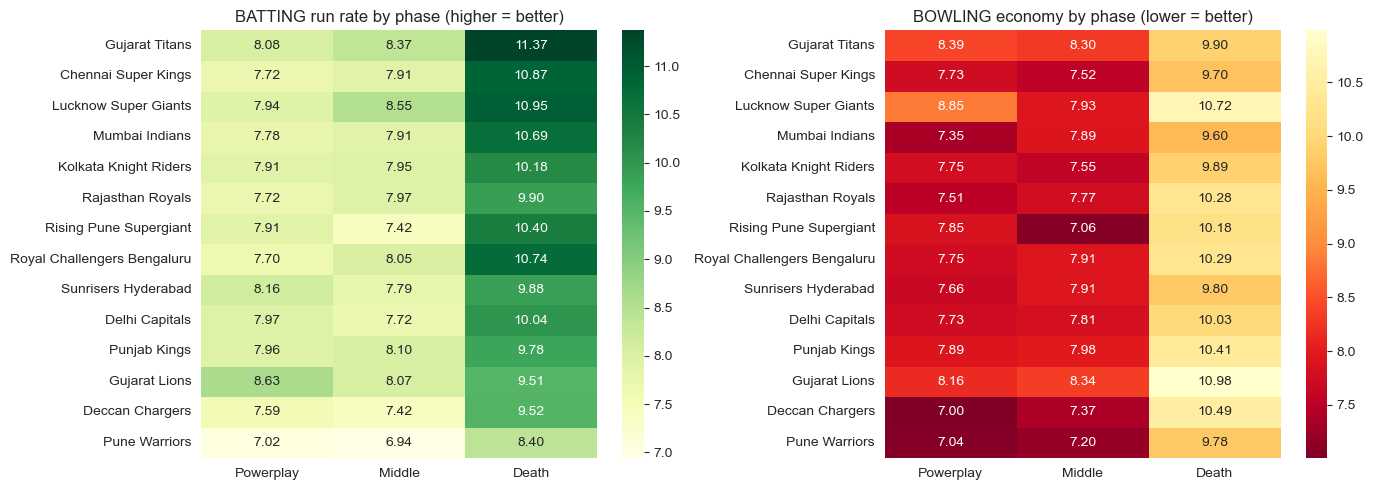

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(team_overall[["pp_rr", "mid_rr", "death_rr"]], annot=True, fmt=".2f", cmap="YlGn", ax=ax[0],
            xticklabels=["Powerplay", "Middle", "Death"])
ax[0].set_title("BATTING run rate by phase (higher = better)")
ax[0].set_ylabel("")

sns.heatmap(team_overall[["pp_econ", "mid_econ", "death_econ"]], annot=True, fmt=".2f", cmap="YlOrRd_r", ax=ax[1],
            xticklabels=["Powerplay", "Middle", "Death"])
ax[1].set_title("BOWLING economy by phase (lower = better)")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 4.3 Batting first vs chasing, team by team
For each team: average run rate and win % in each role. A big gap means the team is much better in one role.

In [20]:
role = (inn.groupby(["batting_team", "inning"])
           .agg(innings=("won", "count"), win_pct=("won", lambda x: x.mean() * 100), run_rate=("run_rate", "mean"))
           .unstack("inning"))
role.columns = ["innings_bat_first", "innings_chase", "win%_bat_first", "win%_chase", "rr_bat_first", "rr_chase"]
role = role[role["innings_bat_first"] >= 30]
role["win%_gap (chase - bat first)"] = role["win%_chase"] - role["win%_bat_first"]
role = role.drop(columns=["innings_bat_first", "innings_chase"]).sort_values("win%_gap (chase - bat first)", ascending=False).round(1)
role

,win%_bat_first,win%_chase,rr_bat_first,rr_chase,win%_gap (chase - bat first)
batting_team,,,,,
Kolkata Knight Riders,44.2,59.5,8.4,8.3,15.4
Rajasthan Royals,43.7,57.8,8.2,8.2,14.1
Punjab Kings,39.8,51.7,8.3,8.5,11.9
Chennai Super Kings,53.8,63.6,8.5,8.2,9.7
Royal Challengers Bengaluru,45.3,52.4,8.6,8.3,7.1
Delhi Capitals,43.2,48.2,8.2,8.2,5.0
Sunrisers Hyderabad,46.8,50.0,8.5,8.2,3.2
Mumbai Indians,53.7,56.7,8.3,8.4,3.0
Deccan Chargers,41.9,34.4,7.9,7.8,-7.5


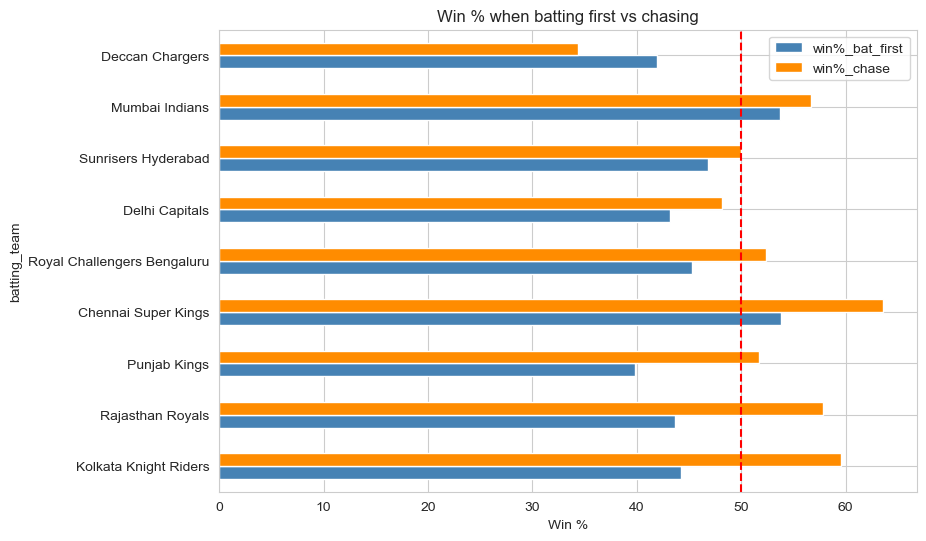

In [21]:
role[["win%_bat_first", "win%_chase"]].plot(kind="barh", figsize=(9, 6), color=["steelblue", "darkorange"])
plt.axvline(50, color="red", linestyle="--")
plt.title("Win % when batting first vs chasing")
plt.xlabel("Win %")
plt.show()

### 4.4 Bowling attack profile – how do teams take wickets?
Share of each dismissal type in the wickets taken by each bowling side.

In [22]:
wk = bb[(bb["is_wicket"] == 1) & (bb["bowling_team"].isin(team_overall.index))]
mix = pd.crosstab(wk["bowling_team"], wk["dismissal_kind"], normalize="index") * 100
mix = mix[["caught", "bowled", "lbw", "run out", "stumped"]].round(1)
mix.loc[team_overall.index]

dismissal_kind,caught,bowled,lbw,run out,stumped
team,,,,,
Gujarat Titans,66.1,13.1,7.4,7.4,2.3
Chennai Super Kings,64.5,15.4,6.4,8.1,2.5
Lucknow Super Giants,72.7,13.6,3.4,5.7,2.7
Mumbai Indians,61.1,17.7,6.4,8.1,2.6
Kolkata Knight Riders,58.4,18.8,7.3,9.0,3.4
Rajasthan Royals,61.9,16.4,5.6,8.9,3.3
Rising Pune Supergiant,57.1,16.4,8.5,10.1,3.7
Royal Challengers Bengaluru,64.4,15.7,5.7,8.4,3.0
Sunrisers Hyderabad,63.6,17.2,7.0,8.2,1.6


## 5. Hypothesis Testing

We use a significance level of **alpha = 0.05**. The unit of analysis is an **innings** (from the innings-level table). Each innings is labelled `won = 1` if the batting side went on to win the match.

*Note:* the two innings of one match are not fully independent, so p-values should be read as a guide rather than an exact probability.

A small helper reports Welch's t-test together with an effect size (Cohen's d), because with ~2,000 innings even tiny differences become "significant" and we want to know whether the gap is also *big*.

In [23]:
def welch(a, b, name_a, name_b, metric):
    a, b = a.dropna(), b.dropna()
    t, p = stats.ttest_ind(a, b, equal_var=False)
    eff = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    print(f"{metric}")
    print(f"  {name_a:28s}: mean = {a.mean():.2f}  (n = {len(a)})")
    print(f"  {name_b:28s}: mean = {b.mean():.2f}  (n = {len(b)})")
    print(f"  t = {t:.2f}, p-value = {p:.6f}, Cohen's d = {eff:.2f}")
    print("  ->", "Reject H0 (significant difference)" if p < 0.05 else "Fail to reject H0")

### H1: Winning innings are scored at a higher run rate
- **H0:** Mean innings run rate is the same in winning and losing innings
- **H1:** The means are different

In [24]:
welch(inn.loc[inn["won"] == 1, "run_rate"], inn.loc[inn["won"] == 0, "run_rate"],
      "Innings in a win", "Innings in a loss", "Innings run rate")

Innings run rate
  Innings in a win            : mean = 8.89  (n = 1090)
  Innings in a loss           : mean = 7.74  (n = 1090)
  t = 18.87, p-value = 0.000000, Cohen's d = 0.81
  -> Reject H0 (significant difference)


### H2: Winning innings have a lower dot-ball percentage
- **H0:** Mean dot-ball % is the same in winning and losing innings
- **H1:** The means are different

In [25]:
welch(inn.loc[inn["won"] == 1, "dot_pct"], inn.loc[inn["won"] == 0, "dot_pct"],
      "Innings in a win", "Innings in a loss", "Dot-ball % of the innings")

Dot-ball % of the innings
  Innings in a win            : mean = 34.08  (n = 1090)
  Innings in a loss           : mean = 38.04  (n = 1090)
  t = -12.81, p-value = 0.000000, Cohen's d = -0.55
  -> Reject H0 (significant difference)


### H3: Scoring rate differs between batting first and chasing
- **H0:** Mean run rate is the same in the first and second innings
- **H1:** The means are different

In [26]:
welch(inn.loc[inn["inning"] == 1, "run_rate"], inn.loc[inn["inning"] == 2, "run_rate"],
      "First innings", "Second innings (chase)", "Innings run rate")

Innings run rate
  First innings               : mean = 8.36  (n = 1090)
  Second innings (chase)      : mean = 8.28  (n = 1090)
  t = 1.19, p-value = 0.232716, Cohen's d = 0.05
  -> Fail to reject H0


### H4: Losing 3 or more wickets in the powerplay is related to losing the match
- **H0:** Match result (for the batting side) is independent of whether it lost 3+ wickets in the powerplay
- **H1:** They are dependent

Test: chi-square test of independence.

In [27]:
inn["pp_wkts"] = inn["pp_wkts"].fillna(0)
inn["pp_collapse"] = np.where(inn["pp_wkts"] >= 3, "3+ wickets lost in PP", "0-2 wickets lost in PP")

table = pd.crosstab(inn["pp_collapse"], inn["won"])
table.columns = ["Lost", "Won"]
print(table)
print()
print((inn.groupby("pp_collapse")["won"].mean() * 100).round(1).rename("win %").to_string())

chi2, p, dof, expected = stats.chi2_contingency(table)
print(f"\nchi2 = {chi2:.3f}, dof = {dof}, p-value = {p:.6f}")
print("->", "Reject H0: powerplay collapses and results are related" if p < 0.05 else "Fail to reject H0")

                        Lost   Won
pp_collapse                       
0-2 wickets lost in PP   822  1002
3+ wickets lost in PP    268    88

pp_collapse
0-2 wickets lost in PP    54.9
3+ wickets lost in PP     24.7

chi2 = 107.569, dof = 1, p-value = 0.000000
-> Reject H0: powerplay collapses and results are related


### H5: Scoring has changed over time
- **H0:** Mean innings run rate is the same in 2008-2015 and 2016 onwards
- **H1:** It is different

In [28]:
welch(inn.loc[inn["year"] <= 2015, "run_rate"], inn.loc[inn["year"] > 2015, "run_rate"],
      "2008-2015", "2016 onwards", "Innings run rate")

Innings run rate
  2008-2015                   : mean = 7.97  (n = 1028)
  2016 onwards                : mean = 8.62  (n = 1152)
  t = -10.03, p-value = 0.000000, Cohen's d = -0.43
  -> Reject H0 (significant difference)


### H6: Franchises differ in their batting run rate
- **H0:** All franchises have the same mean innings run rate
- **H1:** At least one franchise is different

Test: one-way ANOVA across franchises with at least 100 innings.

In [29]:
counts = inn["batting_team"].value_counts()
big_teams = counts[counts >= 100].index
groups = [inn.loc[inn["batting_team"] == t, "run_rate"].dropna() for t in big_teams]

f, p = stats.f_oneway(*groups)
print(f"{len(big_teams)} franchises compared")
print(f"F = {f:.2f}, p-value = {p:.4f}")
print("->", "Reject H0: franchises differ in batting run rate" if p < 0.05 else "Fail to reject H0: differences between franchises are within normal variation")

inn[inn["batting_team"].isin(big_teams)].groupby("batting_team")["run_rate"].mean().sort_values(ascending=False).round(2)

8 franchises compared
F = 0.62, p-value = 0.7391
-> Fail to reject H0: differences between franchises are within normal variation


batting_team
Royal Challengers Bengaluru    8.44
Mumbai Indians                 8.39
Chennai Super Kings            8.39
Punjab Kings                   8.38
Kolkata Knight Riders          8.35
Sunrisers Hyderabad            8.33
Rajasthan Royals               8.22
Delhi Capitals                 8.22
Name: run_rate, dtype: float64

### H7: Which phase separates winners from losers the most?
For each phase we compare the run rate of winning and losing innings. A larger effect size means that phase matters more.

In [30]:
rows = []
for col, name in [("pp_rr", "Powerplay"), ("mid_rr", "Middle overs"), ("death_rr", "Death overs")]:
    a = inn.loc[inn["won"] == 1, col].dropna()
    b = inn.loc[inn["won"] == 0, col].dropna()
    t, p = stats.ttest_ind(a, b, equal_var=False)
    eff = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    rows.append({"phase": name, "run rate in wins": a.mean(), "run rate in losses": b.mean(),
                 "difference": a.mean() - b.mean(), "p-value": p, "Cohen's d": eff})
phase_gap = pd.DataFrame(rows).set_index("phase").round(3)
phase_gap

,run rate in wins,run rate in losses,difference,p-value,Cohen's d
phase,,,,,
Powerplay,8.333,7.371,0.962,0.0,0.470
Middle overs,8.438,7.412,1.026,0.0,0.578
Death overs,11.537,9.049,2.487,0.0,0.727


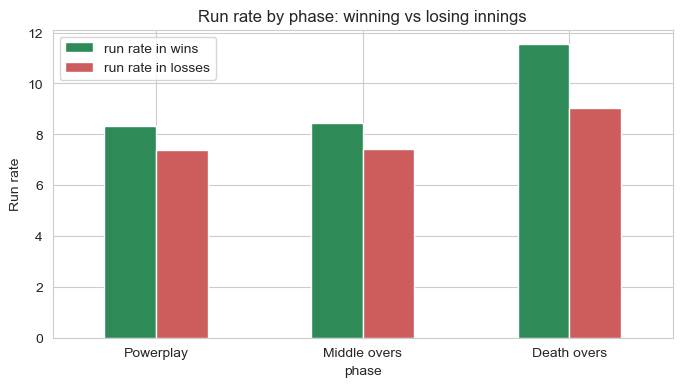

In [31]:
phase_gap[["run rate in wins", "run rate in losses"]].plot(kind="bar", figsize=(8, 4), color=["seagreen", "indianred"])
plt.ylabel("Run rate")
plt.title("Run rate by phase: winning vs losing innings")
plt.xticks(rotation=0)
plt.show()

## 6. Team Performance Index (rule-based)

Instead of a machine-learning model, we build a **transparent, rule-based scoring system**. Nothing is "trained", and every part can be explained to a coach or a broadcaster.

**Step 1 - Standardise.** Each ball-by-ball metric is converted to a z-score (how many standard deviations a team is above or below the average team). Metrics where *lower is better* (dot-ball % when batting, economy, bowling strike rate) are flipped so that **positive always means good**.

**Step 2 - Combine with fixed weights.**

| Index | Components (each weighted equally) |
|---|---|
| **Batting Index** | overall run rate, powerplay run rate, death-over run rate, boundary %, dot-ball % (flipped) |
| **Bowling Index** | economy (flipped), bowling strike rate (flipped), powerplay economy (flipped), death economy (flipped), dot-ball % bowled |
| **Performance Index** | 50% Batting Index + 50% Bowling Index |

**Step 3 - Apply rules to label teams.**

| Performance Index | Tier |
|---|---|
| 0.50 or more | Elite |
| 0.15 to 0.50 | Strong |
| -0.15 to 0.15 | Average |
| below -0.15 | Struggling |

If Batting Index minus Bowling Index is above 0.3 the team is called **batting-led**; below -0.3 it is **bowling-led**; otherwise **balanced**.

**Step 4 - Validate.** The index uses only ball-by-ball performance, never the win/loss column. If it is a good measure of performance, it should still agree with actual win %.

For team-seasons we standardise **within each season**, so a team is compared with the other teams of the same year and the general rise in scoring does not distort the index.

In [32]:
BAT = {"bat_rr": 1, "pp_rr": 1, "death_rr": 1, "bat_boundary_pct": 1, "bat_dot_pct": -1}
BOWL = {"econ": -1, "bowl_sr": -1, "pp_econ": -1, "death_econ": -1, "bowl_dot_pct": 1}
ALL = {**BAT, **BOWL}


def z(s):
    return (s - s.mean()) / s.std(ddof=0)


def signed_z(tbl, within=None):
    comp = tbl[list(ALL)]
    Zs = comp.groupby(level=within).transform(z) if within else comp.apply(z)
    return Zs * pd.Series(ALL)          # positive = good for every column


def build_index(tbl, within=None):
    sz = signed_z(tbl, within)
    out = tbl.copy()
    out["batting_index"] = sz[list(BAT)].mean(axis=1)
    out["bowling_index"] = sz[list(BOWL)].mean(axis=1)
    out["performance_index"] = 0.5 * out["batting_index"] + 0.5 * out["bowling_index"]
    out["tier"] = pd.cut(out["performance_index"], bins=[-np.inf, -0.15, 0.15, 0.50, np.inf],
                         labels=["Struggling", "Average", "Strong", "Elite"])
    gap = out["batting_index"] - out["bowling_index"]
    out["profile"] = np.where(gap > 0.3, "Batting-led", np.where(gap < -0.3, "Bowling-led", "Balanced"))
    return out, sz


team_idx, team_sz = build_index(team_overall)

show = ["batting_index", "bowling_index", "performance_index", "tier", "profile", "win_pct"]
team_idx[show].sort_values("performance_index", ascending=False).round(2)

,batting_index,bowling_index,performance_index,tier,profile,win_pct
team,,,,,,
Gujarat Titans,1.42,-0.05,0.68,Elite,Batting-led,62.22
Mumbai Indians,0.12,0.75,0.44,Strong,Bowling-led,55.17
Chennai Super Kings,0.26,0.62,0.44,Strong,Bowling-led,58.23
Sunrisers Hyderabad,0.13,0.27,0.20,Strong,Balanced,48.35
Rising Pune Supergiant,-0.04,0.36,0.16,Strong,Bowling-led,50.00
Kolkata Knight Riders,0.01,0.30,0.16,Strong,Balanced,52.19
Royal Challengers Bengaluru,0.19,-0.08,0.06,Average,Balanced,48.81
Delhi Capitals,-0.03,0.03,0.00,Average,Balanced,46.00
Lucknow Super Giants,0.83,-1.00,-0.09,Average,Batting-led,55.81


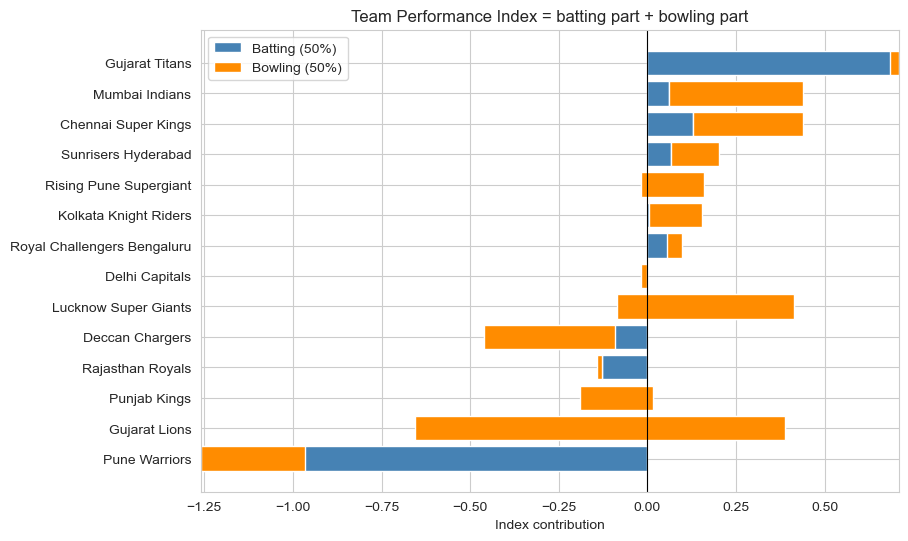

In [33]:
# ranking chart: batting and bowling contribution to the overall index
rank = team_idx.sort_values("performance_index")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(rank.index, rank["batting_index"] * 0.5, color="steelblue", label="Batting (50%)")
ax.barh(rank.index, rank["bowling_index"] * 0.5, left=rank["batting_index"].clip(upper=0) * 0 + rank["batting_index"] * 0.5,
        color="darkorange", label="Bowling (50%)")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Team Performance Index = batting part + bowling part")
ax.set_xlabel("Index contribution")
ax.legend()
plt.show()

### 6.1 Does the index agree with winning?
We build the same index for every **team-season** (a franchise in one year, with at least 8 matches) and compare it with that season's win %. The index never saw the result column, so agreement here is real evidence that it measures performance.

In [34]:
team_season = (batting_metrics(["batting_team", "year"]).join(bowling_metrics(["bowling_team", "year"]))
               .join(season_record))
team_season = team_season[team_season["matches"] >= 8].copy()

season_idx, season_sz = build_index(team_season, within="year")
print("team-seasons:", len(season_idx))

rho, p = stats.spearmanr(season_idx["performance_index"], season_idx["win_pct"])
print(f"Performance Index vs win %  : Spearman rho = {rho:.2f}, p-value = {p:.2e}")
for c in ["batting_index", "bowling_index"]:
    r_, p_ = stats.spearmanr(season_idx[c], season_idx["win_pct"])
    print(f"{c:18s} vs win %  : Spearman rho = {r_:.2f}, p-value = {p_:.2e}")

# how much of the variation in win % do the two sub-indices explain?
X = np.column_stack([np.ones(len(season_idx)), season_idx["batting_index"], season_idx["bowling_index"]])
y = season_idx["win_pct"].values
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
r2 = 1 - ((y - X @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"\nwin % = {coef[0]:.1f} + {coef[1]:.1f} x batting_index + {coef[2]:.1f} x bowling_index   (R-squared = {r2:.2f})")

team-seasons: 146
Performance Index vs win %  : Spearman rho = 0.73, p-value = 2.75e-25
batting_index      vs win %  : Spearman rho = 0.47, p-value = 1.54e-09
bowling_index      vs win %  : Spearman rho = 0.48, p-value = 7.25e-10

win % = 49.3 + 9.7 x batting_index + 11.2 x bowling_index   (R-squared = 0.56)


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c, title in zip(ax, ["performance_index", "batting_index", "bowling_index"],
                       ["Performance Index", "Batting Index", "Bowling Index"]):
    sns.regplot(data=season_idx, x=c, y="win_pct", ax=a, scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
    a.set_title(f"{title} vs season win %")
    a.set_ylabel("Win %")
plt.tight_layout()
plt.show()

In [35]:
# accuracy of the tiers: average win % in each tier
tier_check = (season_idx.groupby("tier", observed=True)["win_pct"].agg(["mean", "count"]).round(1))
tier_check.columns = ["average win %", "team-seasons"]
tier_check

,average win %,team-seasons
tier,,
Struggling,38.8,54
Average,48.9,32
Strong,56.1,40
Elite,64.7,20


### 6.2 Which performance measures move with winning?
Rank correlation between each (season-standardised, sign-corrected) component and season win %. All bars should be positive; the longer the bar, the more that skill is tied to winning.

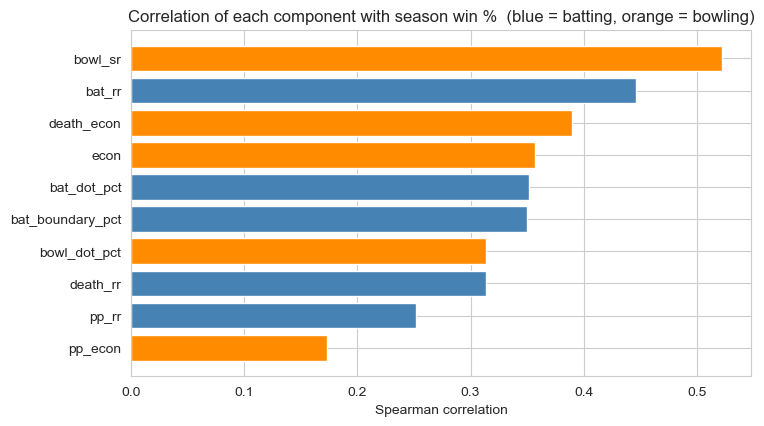

bowl_sr             0.52
bat_rr              0.45
death_econ          0.39
econ                0.36
bat_boundary_pct    0.35
bat_dot_pct         0.35
death_rr            0.31
bowl_dot_pct        0.31
pp_rr               0.25
pp_econ             0.17
dtype: float64

In [36]:
comp_corr = season_sz.corrwith(season_idx["win_pct"], method="spearman").sort_values()

plt.figure(figsize=(8, 4.5))
colors = ["steelblue" if c in BAT else "darkorange" for c in comp_corr.index]
plt.barh(comp_corr.index, comp_corr.values, color=colors)
plt.title("Correlation of each component with season win %  (blue = batting, orange = bowling)")
plt.xlabel("Spearman correlation")
plt.show()
comp_corr.round(2).sort_values(ascending=False)

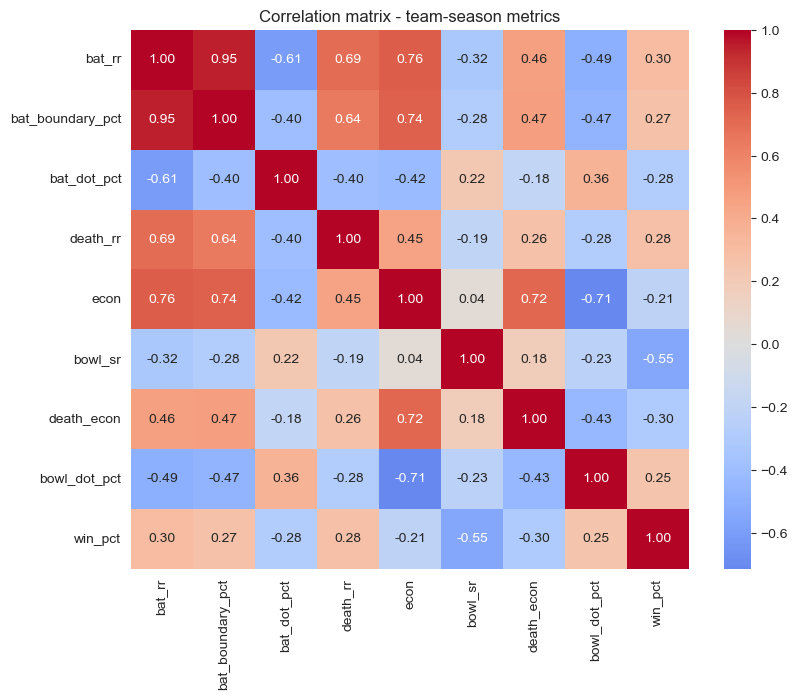

In [37]:
# correlation between raw team-season metrics
cols = ["bat_rr", "bat_boundary_pct", "bat_dot_pct", "death_rr", "econ", "bowl_sr", "death_econ", "bowl_dot_pct", "win_pct"]
plt.figure(figsize=(9, 7))
sns.heatmap(season_idx[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix - team-season metrics")
plt.show()

### 6.3 Team trajectories over the seasons
How the Performance Index of each long-running franchise moved from year to year (0 = average team of that season).

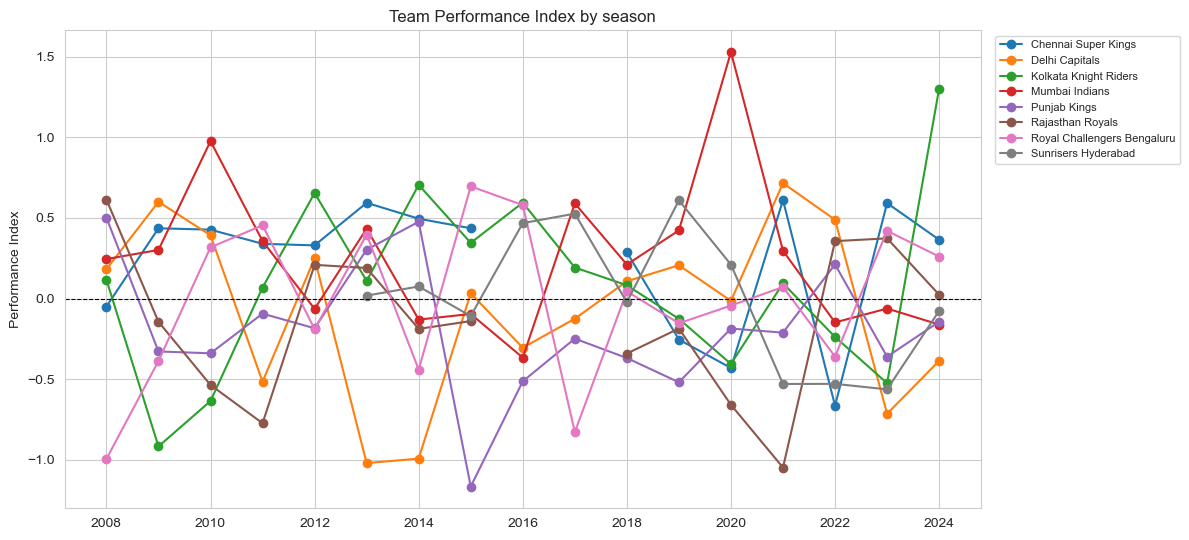

In [38]:
traj = season_idx["performance_index"].unstack("team")
long_running = traj.columns[traj.notna().sum() >= 10]

plt.figure(figsize=(12, 5.5))
for t in long_running:
    plt.plot(traj.index, traj[t], marker="o", label=t, linewidth=1.5)
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Team Performance Index by season")
plt.ylabel("Performance Index")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

### 6.4 Team report card
A helper that explains the index for any franchise: its tier, its best and its weakest skill, so that the score is never a black box.

In [39]:
LABELS = {"bat_rr": "overall batting run rate", "pp_rr": "powerplay batting", "death_rr": "death-over batting",
          "bat_boundary_pct": "boundary hitting", "bat_dot_pct": "avoiding dot balls",
          "econ": "overall bowling economy", "bowl_sr": "wicket taking", "pp_econ": "powerplay bowling",
          "death_econ": "death-over bowling", "bowl_dot_pct": "dot-ball bowling"}


def team_report(team):
    r = team_idx.loc[team]
    s = team_sz.loc[team].sort_values()
    print(f"{team}  ({int(r['matches'])} matches, win % = {r['win_pct']:.1f})")
    print(f"  Batting Index     : {r['batting_index']:+.2f}")
    print(f"  Bowling Index     : {r['bowling_index']:+.2f}")
    print(f"  Performance Index : {r['performance_index']:+.2f}  -> {r['tier']}, {r['profile']}")
    print("  Biggest strengths :", ", ".join(f"{LABELS[k]} ({v:+.2f})" for k, v in s.tail(2)[::-1].items()))
    print("  Biggest weaknesses:", ", ".join(f"{LABELS[k]} ({v:+.2f})" for k, v in s.head(2).items()))


for t in team_idx.sort_values("performance_index", ascending=False).index[:3]:
    team_report(t)
    print()

Gujarat Titans  (45 matches, win % = 62.2)
  Batting Index     : +1.42
  Bowling Index     : -0.05
  Performance Index : +0.68  -> Elite, Batting-led
  Biggest strengths : avoiding dot balls (+2.11), death-over batting (+1.65)
  Biggest weaknesses: powerplay bowling (-1.33), overall bowling economy (-1.32)

Mumbai Indians  (261 matches, win % = 55.2)
  Batting Index     : +0.12
  Bowling Index     : +0.75
  Performance Index : +0.44  -> Strong, Bowling-led
  Biggest strengths : death-over bowling (+1.39), powerplay bowling (+0.87)
  Biggest weaknesses: avoiding dot balls (-0.73), powerplay batting (-0.25)

Chennai Super Kings  (237 matches, win % = 58.2)
  Batting Index     : +0.26
  Bowling Index     : +0.62
  Performance Index : +0.44  -> Strong, Bowling-led
  Biggest strengths : death-over bowling (+1.14), death-over batting (+0.97)
  Biggest weaknesses: powerplay batting (-0.42), powerplay bowling (+0.08)

